In [1]:
%matplotlib inline
import os
import re
import itertools
from itertools import combinations
import glob
import pickle
import argparse
import gzip

import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import multiprocess as mp
import numpy as np
import pandas as pd
import bioframe as bf
import cooltools
import cooler
from matplotlib import gridspec
from matplotlib.gridspec import GridSpec
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
from collections import OrderedDict
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:651: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/cooltools/lib/numutils.py:726: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit  # (nopython=True)


In [2]:
#get compartment files (100kb) of 5 stages of bulk HiC (rep 2)
#path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/compartment_bulk"
path = '/pi/job.dekker-umw/home/johan.gibcus-umw/projects/UM1/compartments'
os.chdir(path)
os.getcwd()

stages = ['H1','ES', 'DE','HB','iHep','mHep']

comp = {}
comp['H1'] = pd.read_csv('ESC-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp['ES'] = pd.read_csv('ESC-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp['DE'] = pd.read_csv('DE-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp['HB'] = pd.read_csv('HB-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp['iHep'] = pd.read_csv('iHEP-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)
comp['mHep'] = pd.read_csv('mHEP-FA-DSG-DdeI-DpnII-R2L1-4__hg38.comp.100kb.cis.E1.tsv',sep="\t",comment="#",index_col=None)

print(len(comp['ES'].dropna()))

26984


In [3]:
comp['H1'].dropna()

,chrom,start,end,E1
18,chr1,1800000,1900000,0.827367
19,chr1,1900000,2000000,0.602338
20,chr1,2000000,2100000,0.755854
21,chr1,2100000,2200000,0.541238
22,chr1,2200000,2300000,0.689677
...,...,...,...,...
30537,chrY,21600000,21700000,0.974077
30539,chrY,21800000,21900000,1.088024
30543,chrY,22200000,22300000,1.582336
30544,chrY,22300000,22400000,1.738694


In [4]:
#identify unique_chrom_value
unique_chrom = comp['H1']['chrom'].unique()
#remove chrM from unique_chrom
unique_chrom_nuclei = unique_chrom[:-1]

In [5]:
#split comp_combine table by different chromosomes
def split_df_by_chrom(df):
    # Get unique chromosome values
    unique_chrom_values = df['chrom'].unique()
    
    # Create a dictionary to store the split DataFrames
    split_dfs = {}
    
    # Iterate over unique chromosome values
    for chrom_value in unique_chrom_values:
        # Extract rows with the current chromosome value
        split_df = df[df['chrom'] == chrom_value].copy()
         # Reset index
        split_df.reset_index(drop=True, inplace=True)
        # Store the DataFrame in the dictionary
        split_dfs[chrom_value] = split_df
    return split_dfs

In [6]:
#apply "split_df_by_chrom" function 
comp_split = {}

for stage in stages:
    comp_split[stage] = split_df_by_chrom(comp[stage])

In [7]:
#define a bin combine function (1M = 10, 2M = 20)
def create_continuous_ranges(df, Mg):
    original_list = df.index 
    # Split the indices into lists of length Mg
    index_lists = [original_list[i:i+Mg] for i in range(0, len(original_list), Mg)]

    df_Mg = pd.DataFrame(columns=["chrom", "start", "end", "E1"])
    
    # Loop through the index_lists
    for indices in index_lists:
        start_index = indices[0]
        end_index = indices[-1]       
        # Create a temporary DataFrame for the current continuous range
        df_continues_tmp = pd.DataFrame({
            "chrom": [df['chrom'][start_index]],
            "start": [df['start'][start_index]],
            "end": [df['end'][end_index]],
            "E1": [df['E1'][start_index:end_index].mean()]
        })        
        # Concatenate the temporary DataFrame to the main DataFrame
        df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
        df_Mg['start'] = df_Mg['start'].astype(int)
        df_Mg['end'] = df_Mg['end'].astype(int)
        df_Mg['E1'] = df_Mg['E1'].astype(float)
    
    # Add a Bin_ID column to the DataFrame
    df_Mg["Bin_ID"] = df_Mg["chrom"] + "_Bin" + df_Mg.index.astype(str)
    
    return df_Mg

In [8]:
#apply "create_continuous_ranges" function on comp_split
comp_chrom_bin = {stage: {} for stage in stages}

for stage in stages:
    for chrom in unique_chrom_nuclei:
        comp_chrom_bin[stage][chrom] = create_continuous_ranges(comp_split[stage][chrom], 10)

/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all

/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all

/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all

/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all

/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_Mg = pd.concat([df_Mg, df_continues_tmp], ignore_index=True)
/tmp/ipykernel_843168/1590672614.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all

In [9]:
#get comp bin all 
comp_bin = {}

for stage in stages:
    comp_bin[stage] = pd.concat(comp_chrom_bin[stage].values(), ignore_index=True)
    comp_bin[stage].to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_EGV_{stage}_1M.txt', sep='\t', index=True)

In [10]:
comp_bin[stage]

,chrom,start,end,E1,Bin_ID
0,chr1,0,1000000,NaN,chr1_Bin0
1,chr1,1000000,2000000,1.553887,chr1_Bin1
2,chr1,2000000,3000000,0.671571,chr1_Bin2
3,chr1,3000000,4000000,0.513393,chr1_Bin3
4,chr1,4000000,5000000,-0.206001,chr1_Bin4
...,...,...,...,...,...
3097,chrY,53000000,54000000,NaN,chrY_Bin53
3098,chrY,54000000,55000000,NaN,chrY_Bin54
3099,chrY,55000000,56000000,NaN,chrY_Bin55
3100,chrY,56000000,57000000,-0.081205,chrY_Bin56


In [17]:
bf.is_bedframe(comp_bin[stage])

True

In [12]:
## read single cell data

In [12]:
#ES single cell stages :
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/H1-scHiC-results/pairs_library"

condition = []
for i in range(1, 193):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

ES_dfs = {}
ES_Num_Contacts = [ ]
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    ES_Num_Contacts = ES_Num_Contacts+[Num_Cont]
    ES_dfs[cond] = {'df': df}

In [13]:
#DE single cell stages :
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/DE-HiC-results/pairs_library"

condition = []
for i in range(1, 193):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

DE_dfs = {}
DE_Num_Contacts = [ ]
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    DE_Num_Contacts = DE_Num_Contacts+[Num_Cont]
    DE_dfs[cond] = {'df': df}

In [14]:
#HB single cell stages :
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/HB-HiC-results/pairs_library"

condition = []
for i in range(1, 193):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

HB_dfs = {}
HB_Num_Contacts = [ ]
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    HB_Num_Contacts = HB_Num_Contacts+[Num_Cont]
    HB_dfs[cond] = {'df': df}

In [15]:
#iHep single cell stages :
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/iHep-HiC-results/pairs_library"

condition = []
for i in range(1, 193):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

iHep_dfs = {}
iHep_Num_Contacts = [ ]
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    iHep_Num_Contacts = iHep_Num_Contacts+[Num_Cont]
    iHep_dfs[cond] = {'df': df}

In [16]:
#mHep single cell stages :
path = "/home/xiangru.huo-umw/scHiC/4DN_08122023_HiC/mHep-HiC-results/pairs_library"

condition = []
for i in range(1, 193):
    cond = f"scHiC_cell{i}.hg38.nodups.pairs.gz"
    condition.append(cond)
    
import os
os.chdir(path)
os.getcwd()

pairs_header = ['read_id', 'chrom1', 'pos1', 'chrom2', 'pos2', 'strand1', 'strand2', 'pair_type', 'mapq1', 'mapq2']

mHep_dfs = {}
mHep_Num_Contacts = [ ]
for cond in condition:
    with gzip.open(cond, 'rt') as file:
        df = pd.read_csv(
            f"{path}/{cond}",
            sep="\t",
            header=None,
            comment="#",
            names=pairs_header,
            index_col=None
        )
        df = df[df["pair_type"] == "UU"]
    Num_Cont = len(df)
    mHep_Num_Contacts = mHep_Num_Contacts+[Num_Cont]
    mHep_dfs[cond] = {'df': df}

In [18]:
#organize five stages together
stages = ['H1','ES','DE','HB','iHep','mHep']
stage_combined_dfs = {}
stage_combined_dfs['H1'] = H1_combined_dfs
stage_combined_dfs['ES'] = ES_combined_dfs
stage_combined_dfs['DE'] = DE_combined_dfs
stage_combined_dfs['HB'] = HB_combined_dfs
stage_combined_dfs['iHep'] = iHep_combined_dfs
stage_combined_dfs['mHep'] = mHep_combined_dfs

Contacts_number = {}
Contacts_number['H1'] = H1_Num_Contacts
Contacts_number['ES'] = ES_Num_Contacts
Contacts_number['DE'] = DE_Num_Contacts
Contacts_number['HB'] = HB_Num_Contacts
Contacts_number['iHep'] = iHep_Num_Contacts
Contacts_number['mHep'] = mHep_Num_Contacts

In [19]:
##only keep the cells have > 20K contacts

In [19]:
#1. read interphase/proM info (selected one you want to use)
interphase_cell_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/interphase_cell_5stages_1.txt", sep='\t',index_col=0)
prom_cell_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_cell_5stages_1.txt", sep='\t',index_col=0)

interphase_cell_10k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/interphase_cell_10K_5stages_1.txt", sep='\t',index_col=0)
prom_cell_10k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_cell_10K_5stages_1.txt", sep='\t',index_col=0)

interphase_cell_20k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/interphase_cell_20K_5stages_1.txt", sep='\t',index_col=0)
prom_cell_20k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_cell_20K_5stages_1.txt", sep='\t',index_col=0)

interphase_cell_30k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/interphase_cell_30K_5stages_1.txt", sep='\t',index_col=0)
prom_cell_30k_df = pd.read_csv("/home/xiangru.huo-umw/scHiC/scripts/inter_file/proM_cell_30K_5stages_1.txt", sep='\t',index_col=0)

In [20]:
#Build dictionary of interphase cells (here i used 10K or 30K contacts cells to plot scaling)
Interphase_30K_dict = {}
for stage in interphase_cell_30k_df['stage'].unique():
    stage_df = interphase_cell_30k_df[interphase_cell_30k_df['stage'] == stage]
    plate_dict = {}
    for plate in stage_df['plate'].unique():
        indices = stage_df[stage_df['plate'] == plate].index.tolist()
        plate_dict[plate] = indices
    Interphase_30K_dict[stage] = plate_dict
    
Interphase_20K_dict = {}
for stage in interphase_cell_20k_df['stage'].unique():
    stage_df = interphase_cell_20k_df[interphase_cell_20k_df['stage'] == stage]
    plate_dict = {}
    for plate in stage_df['plate'].unique():
        indices = stage_df[stage_df['plate'] == plate].index.tolist()
        plate_dict[plate] = indices
    Interphase_20K_dict[stage] = plate_dict
    
Interphase_10K_dict = {}
for stage in interphase_cell_10k_df['stage'].unique():
    stage_df = interphase_cell_10k_df[interphase_cell_10k_df['stage'] == stage]
    plate_dict = {}
    for plate in stage_df['plate'].unique():
        indices = stage_df[stage_df['plate'] == plate].index.tolist()
        plate_dict[plate] = indices
    Interphase_10K_dict[stage] = plate_dict

In [ ]:
def adjust_cell_index(df):
    # List of target plate identifiers that need +96 shift
    target_plates = [
        "plate8_H1",
        "plate6_iHep",
        "plate8_mHep",
        "plate8_DE",
        "plate8_HB",
    ]

    new_index = []
    for idx, row in df.iterrows():
        # Check if the plate matches target criteria
        if row["plate+stage"] in target_plates:
            # Extract cell number and suffix (e.g. '8' and '.hg38.nodups.pairs.gz' from 'scHiC_cell8.hg38.nodups.pairs.gz')
            match = re.match(
                r"scHiC_cell(\d+)(\.hg38\.nodups\.pairs\.gz)", str(idx)
            )
            if match:
                cell_num = int(match.group(1)) + 96
                suffix = match.group(2)
                new_idx = f"scHiC_cell{cell_num}{suffix}"
                new_index.append(new_idx)
            else:
                new_index.append(idx)
        else:
            new_index.append(idx)

    df.index = new_index
    return df


# Apply to your dataframes
interphase_cell_20k_df = adjust_cell_index(interphase_cell_20k_df)
prom_cell_20k_df = adjust_cell_index(prom_cell_20k_df)

interphase_cell_30k_df = adjust_cell_index(interphase_cell_30k_df)
prom_cell_30k_df = adjust_cell_index(prom_cell_30k_df)

In [ ]:
#organize five stages together
stages = ['ES','DE','HB','iHep','mHep']
stage_combined_dfs = {}
stage_combined_dfs['ES'] = ES_dfs
stage_combined_dfs['DE'] = DE_dfs
stage_combined_dfs['HB'] = HB_dfs
stage_combined_dfs['iHep'] = iHep_dfs
stage_combined_dfs['mHep'] = mHep_dfs

Contacts_number = {}
Contacts_number['ES'] = ES_Num_Contacts
Contacts_number['DE'] = DE_Num_Contacts
Contacts_number['HB'] = HB_Num_Contacts
Contacts_number['iHep'] = iHep_Num_Contacts
Contacts_number['mHep'] = mHep_Num_Contacts

In [ ]:
#Build dictionary of interphase cells (here i used 10K or 30K contacts cells to plot scaling)
Interphase_30K_dict = {}
for stage in interphase_cell_30k_df['stage'].unique():
    stage_df = interphase_cell_30k_df[interphase_cell_30k_df['stage'] == stage]
    indices = stage_df.index.tolist()
    Interphase_30K_dict[stage] = indices

Interphase_20K_dict = {}
for stage in interphase_cell_20k_df['stage'].unique():
    stage_df = interphase_cell_20k_df[interphase_cell_20k_df['stage'] == stage]  # fixed: was 30k_df
    indices = stage_df.index.tolist()
    Interphase_20K_dict[stage] = indices

In [33]:
#re-organize contacts map into correct order and remove the diagonal
contacts_reorganized = {stage: {} for stage in stages}
contact_dist = 300  # bp threshold (300bp)

for stage in stages:
    for cond in condition:
        df = stage_combined_dfs[stage][cond]['df'].copy()

        # Keep trans contacts (chrom1 != chrom2), OR
        # cis contacts where |pos2 - pos1| > contact_dist
        df_filtered = df[
            (df['chrom1'] != df['chrom2']) |
            ((df['chrom1'] == df['chrom2']) & ((df['pos2'] - df['pos1']).abs() >= contact_dist))
        ]

        contacts_reorganized[stage][cond] = df_filtered

In [34]:
contacts_reorganized[stage][plate][cond]

,read_id,chrom1,pos1,chrom2,pos2,strand1,strand2,pair_type,mapq1,mapq2
31,GWNJ-1012:1034:GW2307283379th:2:1119:13684:9471,chr1,16549070,chr1,16858875,-,-,UU,3,23
44,GWNJ-1012:1034:GW2307283379th:2:2172:23086:29293,chr1,25674824,chr1,26464380,+,+,UR,60,60
55,GWNJ-1012:1034:GW2307283379th:2:1466:26892:1313,chr1,31662902,chr1,35036857,+,+,UU,60,60
112,GWNJ-1012:1034:GW2307283379th:2:1144:32036:5181,chr1,72218220,chr1,72431353,-,-,UU,60,60
167,GWNJ-1012:1034:GW2307283379th:2:1165:7437:18474,chr1,104018823,chr1,104431550,-,-,RU,60,60
...,...,...,...,...,...,...,...,...,...,...
4966,GWNJ-1012:1034:GW2307283379th:2:1346:26702:34741,chrX,129710466,chrX,129712522,+,+,UU,60,60
4968,GWNJ-1012:1034:GW2307283379th:2:1544:7627:20713,chrX,133707573,chrX,133720766,-,-,RU,60,60
4990,GWNJ-1012:1034:GW2307283379th:2:1648:5963:5462,chrY,11329852,chr14_GL000225v1_random,21832,+,-,UU,3,5
4991,GWNJ-1012:1034:GW2307283379th:2:2605:24442:30389,chrY,11643797,chrUn_KI270442v1,115,-,+,UU,19,16


In [35]:
#generate bin id to each contacts per cell
def generate_contacts_bin_id(df):
    # Process 'chrom1' and 'pos1'
    df1 = df[['chrom1', 'pos1']].copy()
    df1.rename(columns={'chrom1': 'chrom', 'pos1': 'start'}, inplace=True)
    df1['end'] = df1['start'] + 1
    df1_binID = bf.overlap(df1, comp_bin[stage], how='left', suffixes=('_1', '_2'))
    df1_binID = df1_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df1_binID.columns = ['chrom1', 'pos1', 'Bin_ID_1']

    # Process 'chrom2' and 'pos2'
    df2 = df[['chrom2', 'pos2']].copy()
    df2.rename(columns={'chrom2': 'chrom', 'pos2': 'start'}, inplace=True)
    df2['end'] = df2['start'] + 1
    df2_binID = bf.overlap(df2, comp_bin[stage], how='left', suffixes=('_1', '_2'))
    df2_binID = df2_binID.loc[:, ['chrom_1', 'start_1', 'Bin_ID_2']].copy()
    df2_binID.columns = ['chrom2', 'pos2', 'Bin_ID_2']

    # Concatenate the results
    df_binID = pd.concat([df1_binID, df2_binID], axis=1)

    return df_binID

In [36]:
# Call the function "generate_contacts_Bin_id" and store the result
stage_contacts_Bin_ID = {stage: {} for stage in stages}

for stage in stages:
    for cond in Interphase_20K_dict[stage]:
        df = contacts_reorganized[stage][cond].copy()
        stage_contacts_Bin_ID[stage][cond] = generate_contacts_bin_id(df)

In [38]:
stage_contacts_Bin_ID['H1']

{'scHiC_cell12.hg38.nodups.pairs.gz':                chrom1       pos1     Bin_ID_1            chrom2       pos2  \
 0                chr1   14414960   chr1_Bin14              chr1   14417524   
 1                chr1   14414968   chr1_Bin14              chr1   14417524   
 2                chr1   14414979   chr1_Bin14              chr1   14417524   
 3                chr1   48268362   chr1_Bin48              chr1   49760999   
 4                chr1   58294386   chr1_Bin58              chr1   58295994   
 ..                ...        ...          ...               ...        ...   
 358              chr9  131130042  chr9_Bin131              chr9  131137097   
 359              chr9  131130045  chr9_Bin131              chr9  131137097   
 360              chr9  133564359  chr9_Bin133              chrX    1160879   
 361  chrUn_KI270438v1     104079         None  chrUn_KI270438v1     110427   
 362  chrUn_KI270466v1       1011         None  chrUn_KI270467v1       2526   
 
         Bin_

In [32]:
#calculate cis/trans ratio of each bin

In [39]:
df = stage_contacts_Bin_ID['H1']['plate6_']['scHiC_cell12.hg38.nodups.pairs.gz'].copy()
df2 = pd.DataFrame(df.groupby('Bin_ID_2')['chrom1'].value_counts())
df2.head(10)

count
Bin_ID_2     chrom1       
chr10_Bin125 chr7        5
             chr6        2
             chr9        1
chr10_Bin20  chr10       1
chr10_Bin31  chr10       1
chr10_Bin45  chr4        1
chr10_Bin5   chr2        1
             chr7        1
chr10_Bin53  chr3        1
chr10_Bin55  chr2        1

In [41]:
unique_chrom1_counts = df.groupby('Bin_ID_2')['chrom1'].nunique().reset_index()

# Rename for clarity
unique_chrom1_counts.columns = ['Bin_ID_2', 'chromosome_count']

# Preview
unique_chrom1_counts.head(10)

,Bin_ID_2,chromosome_count
0,chr10_Bin125,3
1,chr10_Bin20,1
2,chr10_Bin31,1
3,chr10_Bin45,1
4,chr10_Bin5,2
5,chr10_Bin53,1
6,chr10_Bin55,1
7,chr10_Bin64,1
8,chr10_Bin80,1
9,chr10_Bin81,1


In [32]:
#cis use the largest number, trans use Bin_ID_1 + Bin_ID_2

In [42]:
#define the function to get the cis_ratio per cell + count of inter-chromsomes 
def calculate_cis_ratio(df):
    # From pos1 (Bin_ID_1)
    cis_count = df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().max()).reset_index()
    total_count = df.groupby('Bin_ID_1')['chrom2'].apply(lambda x: x.value_counts().sum()).reset_index()
    
    cis_ratio = pd.merge(cis_count, total_count, on='Bin_ID_1', how='outer')
    cis_ratio.columns = ['Bin_ID_1', 'cis_count1', 'total_count1']
    cis_ratio['trans_count1'] = cis_ratio['total_count1'] - cis_ratio['cis_count1']

    # From pos2 (Bin_ID_2)
    cis_count2 = df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().max()).reset_index()
    total_count2 = df.groupby('Bin_ID_2')['chrom1'].apply(lambda x: x.value_counts().sum()).reset_index()
    
    cis_ratio2 = pd.merge(cis_count2, total_count2, on='Bin_ID_2', how='outer')
    cis_ratio2.columns = ['Bin_ID_1', 'cis_count2', 'total_count2']
    cis_ratio2['trans_count2'] = cis_ratio2['total_count2'] - cis_ratio2['cis_count2']

    # 🔹 NEW: Unique chrom1 count per Bin_ID_2 (renamed to Bin_ID_1 for merging)
    unique_chrom1 = df.groupby('Bin_ID_2')['chrom1'].nunique().reset_index()
    unique_chrom1.columns = ['Bin_ID_1', 'Chromosome_counts']

    # Combine all
    cis_ratio_all = pd.merge(cis_ratio, cis_ratio2, on='Bin_ID_1', how='outer')
    cis_ratio_all = pd.merge(cis_ratio_all, unique_chrom1, on='Bin_ID_1', how='left')

    # Final computed columns
    cis_ratio_all['cis_count_final'] = cis_ratio_all[['cis_count1', 'cis_count2']].max(axis=1)
    cis_ratio_all['trans_count_final'] = cis_ratio_all['trans_count1'] + cis_ratio_all['trans_count2']
    cis_ratio_all['total_count_final'] = cis_ratio_all['cis_count_final'] + cis_ratio_all['trans_count_final']
    cis_ratio_all['cis_ratio_final'] = cis_ratio_all['cis_count_final'] / cis_ratio_all['total_count_final']

    return cis_ratio_all

In [43]:
# Call the function "calculate_cis_ratio" and store the result
stage_cis_ratio_Bin_ID = {stage: {} for stage in stages}

for stage in stages:
    for cond in Interphase_20K_dict[stage]:
        df = stage_contacts_Bin_ID[stage][cond].copy()
        stage_cis_ratio_Bin_ID[stage][cond] = calculate_cis_ratio(df)

In [46]:
stage_cis_ratio_Bin_ID[stage][cond]

,Bin_ID_1,cis_count1,total_count1,trans_count1,cis_count2,total_count2,trans_count2,Chromosome_counts,cis_count_final,trans_count_final,total_count_final,cis_ratio_final
0,chr10_Bin1,2.0,5.0,3.0,2.0,3.0,1.0,2.0,2.0,4.0,6.0,0.333333
1,chr10_Bin100,1.0,1.0,0.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,0.500000
2,chr10_Bin101,NaN,NaN,NaN,1.0,1.0,0.0,1.0,1.0,NaN,NaN,NaN
3,chr10_Bin102,3.0,3.0,0.0,3.0,3.0,0.0,1.0,3.0,0.0,3.0,1.000000
4,chr10_Bin103,5.0,7.0,2.0,5.0,9.0,4.0,2.0,5.0,6.0,11.0,0.454545
...,...,...,...,...,...,...,...,...,...,...,...,...
2387,chrY_Bin56,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,1.000000
2388,chrY_Bin6,5.0,5.0,0.0,1.0,1.0,0.0,1.0,5.0,0.0,5.0,1.000000
2389,chrY_Bin7,NaN,NaN,NaN,5.0,5.0,0.0,1.0,5.0,NaN,NaN,NaN
2390,chrY_Bin8,1.0,1.0,0.0,1.0,2.0,1.0,2.0,1.0,1.0,2.0,0.500000


In [ ]:
##concatenate cis_ratio_all['cis_ratio_final'] for per cell, and organize per stage into a matrix

In [ ]:
#get sum of cis_total ratio Bin_ID per cell
cis_ratio_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin[stage]['Bin_ID']})
    for cond in Interphase_20K_dict[stage]:
            df = stage_cis_ratio_Bin_ID[stage][cond]
            df_tmp = df[['Bin_ID_1', 'cis_ratio_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    cis_ratio_Bin_ID_sum[stage] = df_sum  

In [49]:
cis_ratio_Bin_ID_sum[stage]

,plate6_scHiC_cell5.hg38.nodups.pairs.gz,plate6_scHiC_cell9.hg38.nodups.pairs.gz,plate6_scHiC_cell10.hg38.nodups.pairs.gz,plate6_scHiC_cell12.hg38.nodups.pairs.gz,plate6_scHiC_cell14.hg38.nodups.pairs.gz,plate6_scHiC_cell15.hg38.nodups.pairs.gz,plate6_scHiC_cell16.hg38.nodups.pairs.gz,plate6_scHiC_cell17.hg38.nodups.pairs.gz,plate6_scHiC_cell23.hg38.nodups.pairs.gz,plate6_scHiC_cell24.hg38.nodups.pairs.gz,...,plate6_scHiC_cell89.hg38.nodups.pairs.gz,plate6_scHiC_cell90.hg38.nodups.pairs.gz,plate6_scHiC_cell93.hg38.nodups.pairs.gz,plate6_scHiC_cell96.hg38.nodups.pairs.gz,plate8_scHiC_cell6.hg38.nodups.pairs.gz,plate8_scHiC_cell8.hg38.nodups.pairs.gz,plate8_scHiC_cell74.hg38.nodups.pairs.gz,plate8_scHiC_cell75.hg38.nodups.pairs.gz,plate8_scHiC_cell83.hg38.nodups.pairs.gz,plate8_scHiC_cell95.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,0.736842,0.709677,0.766667,0.75,0.511628,0.230769,0.296296,0.458333,0.666667,0.550000,...,0.250000,0.400000,0.869565,0.785714,NaN,NaN,1.000000,1.0,NaN,NaN
chr10_Bin1,0.500000,0.555556,0.666667,NaN,0.975000,0.625000,0.228571,0.722222,0.880000,0.653846,...,0.400000,0.833333,0.731707,0.666667,NaN,1.000000,1.000000,NaN,NaN,0.333333
chr10_Bin10,0.809524,0.704545,0.789474,1.00,0.511111,0.800000,0.388889,0.317073,0.769231,0.404255,...,NaN,0.666667,0.470588,0.375000,NaN,1.000000,1.000000,1.0,NaN,NaN
chr10_Bin100,0.500000,0.650000,0.666667,NaN,0.703704,0.600000,0.500000,0.461538,0.666667,0.480519,...,0.266667,0.392857,0.655172,0.640000,NaN,1.000000,NaN,1.0,NaN,0.500000
chr10_Bin101,0.600000,0.500000,0.411765,0.80,0.588235,0.375000,0.785714,0.538462,1.000000,0.296296,...,0.333333,0.454545,0.625000,0.608696,NaN,1.000000,0.750000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,0.727273,0.538462,0.375000,NaN,0.153846,0.666667,0.200000,0.500000,NaN,0.240000,...,NaN,0.750000,0.875000,NaN,NaN,NaN,NaN,NaN,NaN,1.000000
chrY_Bin7,0.714286,0.769231,0.818182,1.00,0.450000,0.500000,0.235294,0.250000,0.333333,0.555556,...,NaN,0.750000,0.421053,0.363636,NaN,1.000000,1.000000,NaN,NaN,NaN


In [50]:
#get sum of total reads of Bin_ID per cell
reads_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin[stage]['Bin_ID']})
    for cond in Interphase_20K_dict[stage]:
            df = stage_cis_ratio_Bin_ID[stage][cond]
            df_tmp = df[['Bin_ID_1', 'total_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    reads_Bin_ID_sum[stage] = df_sum  

In [74]:
reads_Bin_ID_sum[stage]

,plate6_scHiC_cell5.hg38.nodups.pairs.gz,plate6_scHiC_cell9.hg38.nodups.pairs.gz,plate6_scHiC_cell10.hg38.nodups.pairs.gz,plate6_scHiC_cell12.hg38.nodups.pairs.gz,plate6_scHiC_cell14.hg38.nodups.pairs.gz,plate6_scHiC_cell15.hg38.nodups.pairs.gz,plate6_scHiC_cell17.hg38.nodups.pairs.gz,plate6_scHiC_cell23.hg38.nodups.pairs.gz,plate6_scHiC_cell24.hg38.nodups.pairs.gz,plate6_scHiC_cell25.hg38.nodups.pairs.gz,...,plate6_scHiC_cell71.hg38.nodups.pairs.gz,plate6_scHiC_cell72.hg38.nodups.pairs.gz,plate6_scHiC_cell74.hg38.nodups.pairs.gz,plate6_scHiC_cell75.hg38.nodups.pairs.gz,plate6_scHiC_cell80.hg38.nodups.pairs.gz,plate6_scHiC_cell87.hg38.nodups.pairs.gz,plate6_scHiC_cell96.hg38.nodups.pairs.gz,plate8_scHiC_cell8.hg38.nodups.pairs.gz,plate8_scHiC_cell74.hg38.nodups.pairs.gz,plate8_scHiC_cell75.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,5.0,16.0,21.0,1.0,28.0,9.0,13.0,NaN,23.0,2.0,...,13.0,NaN,17.0,NaN,2.0,NaN,3.0,NaN,NaN,NaN
chr10_Bin1,7.0,NaN,8.0,NaN,NaN,3.0,11.0,14.0,13.0,1.0,...,NaN,NaN,22.0,4.0,NaN,NaN,17.0,NaN,NaN,NaN
chr10_Bin10,4.0,20.0,6.0,NaN,29.0,3.0,32.0,14.0,30.0,NaN,...,11.0,NaN,14.0,3.0,NaN,NaN,17.0,NaN,NaN,NaN
chr10_Bin100,5.0,17.0,10.0,NaN,17.0,10.0,6.0,10.0,59.0,3.0,...,22.0,NaN,9.0,4.0,NaN,NaN,8.0,NaN,NaN,NaN
chr10_Bin101,3.0,18.0,9.0,1.0,14.0,6.0,10.0,NaN,18.0,NaN,...,5.0,NaN,7.0,3.0,NaN,NaN,11.0,NaN,1.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,4.0,13.0,8.0,NaN,13.0,3.0,NaN,NaN,22.0,NaN,...,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin7,NaN,3.0,NaN,NaN,28.0,NaN,9.0,NaN,NaN,NaN,...,NaN,2.0,5.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN


In [52]:
#get sum of total cis_count_final of Bin_ID per cell
cis_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin[stage]['Bin_ID']})
    for cond in Interphase_20K_dict[stage]:
            df = stage_cis_ratio_Bin_ID[stage][cond]
            df_tmp = df[['Bin_ID_1', 'cis_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    cis_Bin_ID_sum[stage] = df_sum 

In [53]:
cis_Bin_ID_sum[stage]

,plate6_scHiC_cell5.hg38.nodups.pairs.gz,plate6_scHiC_cell9.hg38.nodups.pairs.gz,plate6_scHiC_cell10.hg38.nodups.pairs.gz,plate6_scHiC_cell12.hg38.nodups.pairs.gz,plate6_scHiC_cell14.hg38.nodups.pairs.gz,plate6_scHiC_cell15.hg38.nodups.pairs.gz,plate6_scHiC_cell16.hg38.nodups.pairs.gz,plate6_scHiC_cell17.hg38.nodups.pairs.gz,plate6_scHiC_cell23.hg38.nodups.pairs.gz,plate6_scHiC_cell24.hg38.nodups.pairs.gz,...,plate6_scHiC_cell89.hg38.nodups.pairs.gz,plate6_scHiC_cell90.hg38.nodups.pairs.gz,plate6_scHiC_cell93.hg38.nodups.pairs.gz,plate6_scHiC_cell96.hg38.nodups.pairs.gz,plate8_scHiC_cell6.hg38.nodups.pairs.gz,plate8_scHiC_cell8.hg38.nodups.pairs.gz,plate8_scHiC_cell74.hg38.nodups.pairs.gz,plate8_scHiC_cell75.hg38.nodups.pairs.gz,plate8_scHiC_cell83.hg38.nodups.pairs.gz,plate8_scHiC_cell95.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,14.0,22.0,23.0,3.0,22.0,3.0,8.0,11.0,2.0,22.0,...,3.0,6.0,20.0,11.0,NaN,NaN,1.0,2.0,NaN,NaN
chr10_Bin1,9.0,10.0,16.0,1.0,39.0,5.0,8.0,26.0,22.0,17.0,...,2.0,25.0,30.0,28.0,1.0,5.0,2.0,NaN,NaN,2.0
chr10_Bin10,17.0,31.0,15.0,2.0,23.0,8.0,7.0,13.0,20.0,19.0,...,1.0,4.0,16.0,9.0,NaN,1.0,2.0,1.0,NaN,NaN
chr10_Bin100,6.0,26.0,16.0,1.0,19.0,9.0,14.0,6.0,10.0,37.0,...,4.0,11.0,19.0,16.0,NaN,4.0,2.0,1.0,NaN,1.0
chr10_Bin101,6.0,14.0,7.0,4.0,20.0,3.0,22.0,14.0,4.0,8.0,...,2.0,10.0,15.0,14.0,NaN,1.0,3.0,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,8.0,7.0,3.0,NaN,2.0,2.0,1.0,5.0,1.0,6.0,...,NaN,6.0,7.0,1.0,1.0,1.0,NaN,1.0,1.0,5.0
chrY_Bin7,5.0,10.0,9.0,1.0,18.0,1.0,4.0,3.0,2.0,15.0,...,2.0,6.0,8.0,4.0,NaN,1.0,3.0,NaN,2.0,5.0


In [54]:
#get sum of total trans_count_final of Bin_ID per cell
trans_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin[stage]['Bin_ID']})
    for cond in Interphase_20K_dict[stage]:
            df = stage_cis_ratio_Bin_ID[stage][cond]
            df_tmp = df[['Bin_ID_1', 'trans_count_final']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    trans_Bin_ID_sum[stage] = df_sum  

In [55]:
trans_Bin_ID_sum[stage]

,plate6_scHiC_cell5.hg38.nodups.pairs.gz,plate6_scHiC_cell9.hg38.nodups.pairs.gz,plate6_scHiC_cell10.hg38.nodups.pairs.gz,plate6_scHiC_cell12.hg38.nodups.pairs.gz,plate6_scHiC_cell14.hg38.nodups.pairs.gz,plate6_scHiC_cell15.hg38.nodups.pairs.gz,plate6_scHiC_cell16.hg38.nodups.pairs.gz,plate6_scHiC_cell17.hg38.nodups.pairs.gz,plate6_scHiC_cell23.hg38.nodups.pairs.gz,plate6_scHiC_cell24.hg38.nodups.pairs.gz,...,plate6_scHiC_cell89.hg38.nodups.pairs.gz,plate6_scHiC_cell90.hg38.nodups.pairs.gz,plate6_scHiC_cell93.hg38.nodups.pairs.gz,plate6_scHiC_cell96.hg38.nodups.pairs.gz,plate8_scHiC_cell6.hg38.nodups.pairs.gz,plate8_scHiC_cell8.hg38.nodups.pairs.gz,plate8_scHiC_cell74.hg38.nodups.pairs.gz,plate8_scHiC_cell75.hg38.nodups.pairs.gz,plate8_scHiC_cell83.hg38.nodups.pairs.gz,plate8_scHiC_cell95.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,5.0,9.0,7.0,1.0,21.0,10.0,19.0,13.0,1.0,18.0,...,9.0,9.0,3.0,3.0,NaN,NaN,0.0,0.0,NaN,NaN
chr10_Bin1,9.0,8.0,8.0,NaN,1.0,3.0,27.0,10.0,3.0,9.0,...,3.0,5.0,11.0,14.0,NaN,0.0,0.0,NaN,NaN,4.0
chr10_Bin10,4.0,13.0,4.0,0.0,22.0,2.0,11.0,28.0,6.0,28.0,...,NaN,2.0,18.0,15.0,NaN,0.0,0.0,0.0,NaN,NaN
chr10_Bin100,6.0,14.0,8.0,NaN,8.0,6.0,14.0,7.0,5.0,40.0,...,11.0,17.0,10.0,9.0,NaN,0.0,NaN,0.0,NaN,1.0
chr10_Bin101,4.0,14.0,10.0,1.0,14.0,5.0,6.0,12.0,0.0,19.0,...,4.0,12.0,9.0,9.0,NaN,0.0,1.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,3.0,6.0,5.0,NaN,11.0,1.0,4.0,5.0,NaN,19.0,...,NaN,2.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin7,2.0,3.0,2.0,0.0,22.0,1.0,13.0,9.0,4.0,12.0,...,NaN,2.0,11.0,7.0,NaN,0.0,0.0,NaN,NaN,NaN


In [56]:
#get sum of total interact chromosomes of Bin_ID per cell
chromnum_Bin_ID_sum = {stage: {} for stage in stages}

for stage in stages:
    df_sum = pd.DataFrame({"Bin_ID_1": comp_bin[stage]['Bin_ID']})
    for cond in Interphase_20K_dict[stage]:
            df = stage_cis_ratio_Bin_ID[stage][cond]
            df_tmp = df[['Bin_ID_1', 'Chromosome_counts']]  # Selecting multiple columns requires passing them as a list
            df_tmp.columns = ['Bin_ID_1', cond]
            df_sum = pd.merge(df_sum, df_tmp, how='outer', on='Bin_ID_1')
            df_sum = df_sum.sort_values(by='Bin_ID_1')
    df_sum = df_sum.set_index('Bin_ID_1')
    chromnum_Bin_ID_sum[stage] = df_sum  

In [57]:
chromnum_Bin_ID_sum[stage]

,plate6_scHiC_cell5.hg38.nodups.pairs.gz,plate6_scHiC_cell9.hg38.nodups.pairs.gz,plate6_scHiC_cell10.hg38.nodups.pairs.gz,plate6_scHiC_cell12.hg38.nodups.pairs.gz,plate6_scHiC_cell14.hg38.nodups.pairs.gz,plate6_scHiC_cell15.hg38.nodups.pairs.gz,plate6_scHiC_cell16.hg38.nodups.pairs.gz,plate6_scHiC_cell17.hg38.nodups.pairs.gz,plate6_scHiC_cell23.hg38.nodups.pairs.gz,plate6_scHiC_cell24.hg38.nodups.pairs.gz,...,plate6_scHiC_cell89.hg38.nodups.pairs.gz,plate6_scHiC_cell90.hg38.nodups.pairs.gz,plate6_scHiC_cell93.hg38.nodups.pairs.gz,plate6_scHiC_cell96.hg38.nodups.pairs.gz,plate8_scHiC_cell6.hg38.nodups.pairs.gz,plate8_scHiC_cell8.hg38.nodups.pairs.gz,plate8_scHiC_cell74.hg38.nodups.pairs.gz,plate8_scHiC_cell75.hg38.nodups.pairs.gz,plate8_scHiC_cell83.hg38.nodups.pairs.gz,plate8_scHiC_cell95.hg38.nodups.pairs.gz
Bin_ID_1,,,,,,,,,,,,,,,,,,,,,
chr10_Bin0,3.0,2.0,4.0,2.0,6.0,5.0,6.0,3.0,1.0,8.0,...,5.0,4.0,1.0,3.0,NaN,NaN,1.0,1.0,NaN,NaN
chr10_Bin1,3.0,1.0,4.0,1.0,1.0,3.0,4.0,5.0,3.0,2.0,...,4.0,3.0,3.0,5.0,1.0,1.0,1.0,NaN,NaN,2.0
chr10_Bin10,1.0,7.0,4.0,1.0,4.0,2.0,6.0,6.0,5.0,7.0,...,1.0,1.0,5.0,7.0,NaN,1.0,1.0,1.0,NaN,NaN
chr10_Bin100,2.0,4.0,4.0,NaN,4.0,3.0,4.0,4.0,2.0,6.0,...,6.0,4.0,3.0,5.0,NaN,1.0,NaN,1.0,NaN,2.0
chr10_Bin101,3.0,7.0,5.0,1.0,4.0,5.0,3.0,3.0,1.0,4.0,...,3.0,3.0,5.0,4.0,NaN,1.0,1.0,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
chrY_Bin57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chrY_Bin6,3.0,7.0,4.0,NaN,9.0,2.0,5.0,4.0,2.0,11.0,...,NaN,3.0,2.0,1.0,2.0,1.0,NaN,1.0,1.0,1.0
chrY_Bin7,2.0,4.0,3.0,1.0,14.0,2.0,8.0,7.0,5.0,10.0,...,3.0,3.0,7.0,8.0,NaN,1.0,1.0,NaN,3.0,1.0


In [58]:
#organized table
stages2= ['ES','DE','HB','iHep','mHep']
stage_cis_ratio_Bin_ID_sum = {}
stage_cis_ratio_Bin_ID_sum['ES'] = cis_ratio_Bin_ID_sum['ES'].add_prefix('ES_').transpose()
stage_cis_ratio_Bin_ID_sum['DE'] = cis_ratio_Bin_ID_sum['DE'].add_prefix('DE_').transpose()
stage_cis_ratio_Bin_ID_sum['HB'] = cis_ratio_Bin_ID_sum['HB'].add_prefix('HB_').transpose()
stage_cis_ratio_Bin_ID_sum['iHep'] = cis_ratio_Bin_ID_sum['iHep'].add_prefix('iHep_').transpose()
stage_cis_ratio_Bin_ID_sum['mHep'] = cis_ratio_Bin_ID_sum['mHep'].add_prefix('mHep_').transpose()

In [59]:
#organized total counts
stages2= ['ES','DE','HB','iHep','mHep']
stage_reads_Bin_ID_sum = {}
stage_reads_Bin_ID_sum['ES'] = reads_Bin_ID_sum['ES'].add_prefix('ES_').transpose()
stage_reads_Bin_ID_sum['DE'] = reads_Bin_ID_sum['DE'].add_prefix('DE_').transpose()
stage_reads_Bin_ID_sum['HB'] = reads_Bin_ID_sum['HB'].add_prefix('HB_').transpose()
stage_reads_Bin_ID_sum['iHep'] = reads_Bin_ID_sum['iHep'].add_prefix('iHep_').transpose()
stage_reads_Bin_ID_sum['mHep'] = reads_Bin_ID_sum['mHep'].add_prefix('mHep_').transpose()

In [60]:
#organized cis counts
stages2= ['ES','DE','HB','iHep','mHep']
stage_cis_Bin_ID_sum = {}
stage_cis_Bin_ID_sum['ES'] = cis_Bin_ID_sum['ES'].add_prefix('ES_').transpose()
stage_cis_Bin_ID_sum['DE'] = cis_Bin_ID_sum['DE'].add_prefix('DE_').transpose()
stage_cis_Bin_ID_sum['HB'] = cis_Bin_ID_sum['HB'].add_prefix('HB_').transpose()
stage_cis_Bin_ID_sum['iHep'] = cis_Bin_ID_sum['iHep'].add_prefix('iHep_').transpose()
stage_cis_Bin_ID_sum['mHep'] = cis_Bin_ID_sum['mHep'].add_prefix('mHep_').transpose()

In [62]:
#save stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1kb, 200kb, or 1M)
stages2= ['ES','DE','HB','iHep','mHep']
for stage in stages2:
    dfs = stage_cis_ratio_Bin_ID_sum[stage]
    dfs.to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/cis_ratio_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt', sep='\t', index=True)
    dfs2 = reads_Bin_ID_sum[stage]
    dfs2.to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_reads_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt', sep='\t', index=True)
    dfs3 = cis_Bin_ID_sum[stage]
    dfs3.to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_cis_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt', sep='\t', index=True)
    dfs4 = trans_Bin_ID_sum[stage]
    dfs4.to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_trans_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt', sep='\t', index=True)
    dfs5 = chromnum_Bin_ID_sum[stage]
    dfs5.to_csv(f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_chromnum_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt', sep='\t', index=True)

In [ ]:
#read stage_cis_ratio_Bin_ID_sum into .csv (needs to take care 1M or 2M)
#contact_dist = 200000
stages2 = ['ES', 'DE', 'HB', 'iHep', 'mHep']
stage_cis_ratio_Bin_ID_sum = {}
stage_reads_Bin_ID_sum = {}
contact_dist = 300

# Read each CSV file into a DataFrame and store it in the stage_cis_ratio_Bin_ID_sum dictionary
for stage in stages2:
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/cis_ratio_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    df = pd.read_csv(file_path, sep='\t',index_col=0)
    stage_cis_ratio_Bin_ID_sum[stage] = df
    file_path2 = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/total_reads_perBin_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    df2 = pd.read_csv(file_path2, sep='\t',index_col=0)
    stage_reads_Bin_ID_sum[stage] = df2

In [12]:
stage_cis_ratio_Bin_ID_sum['ES'] = stage_cis_ratio_Bin_ID_sum['ES'][~stage_cis_ratio_Bin_ID_sum['ES'].index.str.startswith('H1')]
stage_cis_ratio_Bin_ID_sum['ES']

,chr10_Bin0,chr10_Bin1,chr10_Bin10,chr10_Bin100,chr10_Bin101,chr10_Bin102,chr10_Bin103,chr10_Bin104,chr10_Bin105,chr10_Bin106,...,chrY_Bin52,chrY_Bin53,chrY_Bin54,chrY_Bin55,chrY_Bin56,chrY_Bin57,chrY_Bin6,chrY_Bin7,chrY_Bin8,chrY_Bin9
ES_plate6_scHiC_cell2.hg38.nodups.pairs.gz,0.794118,0.916667,0.800000,1.000000,0.555556,0.818182,0.500000,0.900000,1.000000,0.666667,...,NaN,NaN,NaN,NaN,0.600000,NaN,0.750000,1.000,0.833333,1.000000
ES_plate6_scHiC_cell8.hg38.nodups.pairs.gz,0.500000,1.000000,0.764706,0.813953,0.727273,0.733333,0.314286,0.666667,0.833333,0.583333,...,NaN,NaN,NaN,NaN,0.558824,NaN,0.666667,0.500,0.750000,0.750000
ES_plate6_scHiC_cell9.hg38.nodups.pairs.gz,0.600000,0.916667,0.888889,0.800000,0.937500,0.666667,0.739130,0.736842,0.944444,0.916667,...,NaN,NaN,NaN,NaN,1.000000,NaN,1.000000,1.000,0.750000,0.800000
ES_plate6_scHiC_cell10.hg38.nodups.pairs.gz,0.823529,0.928571,1.000000,0.800000,0.733333,0.882353,0.727273,1.000000,1.000000,0.888889,...,NaN,NaN,NaN,NaN,1.000000,NaN,0.750000,1.000,0.857143,1.000000
ES_plate6_scHiC_cell11.hg38.nodups.pairs.gz,0.933333,0.818182,0.916667,0.923077,1.000000,0.818182,1.000000,1.000000,0.888889,0.900000,...,NaN,NaN,NaN,NaN,0.750000,NaN,NaN,0.500,1.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ES_plate8_scHiC_cell87.hg38.nodups.pairs.gz,0.800000,0.833333,0.900000,0.750000,0.733333,0.619048,0.823529,0.826087,0.850000,0.733333,...,NaN,NaN,NaN,NaN,NaN,NaN,0.500000,1.000,0.666667,0.500000
ES_plate8_scHiC_cell89.hg38.nodups.pairs.gz,0.625000,0.818182,0.666667,0.750000,0.666667,0.666667,0.888889,0.800000,0.833333,1.000000,...,NaN,NaN,NaN,NaN,0.500000,NaN,NaN,0.500,0.750000,0.333333
ES_plate8_scHiC_cell94.hg38.nodups.pairs.gz,1.000000,0.833333,0.833333,0.882353,0.750000,0.777778,0.666667,0.750000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,0.333333,NaN,NaN,0.800,0.333333,NaN
ES_plate8_scHiC_cell95.hg38.nodups.pairs.gz,0.642857,0.843750,0.800000,0.888889,0.750000,0.937500,1.000000,0.360656,1.000000,0.714286,...,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,1.000,NaN,0.700000


# check interacted unique chromosome number as a function of trans counts
--> if random interaction, it will not be satuated. 

In [13]:
#organize comp_bin_cisratio with EGV together
comp_bin_cisratio = {}
for stage in stages2:
    df = comp_bin[stage].copy()
    df.set_index('Bin_ID', inplace=True)
    df['cisratio_mean'] = stage_cis_ratio_Bin_ID_sum[stage].mean()
    df['cisratio_S.D.'] = stage_cis_ratio_Bin_ID_sum[stage].std()
    df['cisratio_cv'] = df['cisratio_S.D.']/df['cisratio_mean']
    df['cisratio_IQR'] = (stage_cis_ratio_Bin_ID_sum[stage].quantile(0.75, axis=0)- stage_cis_ratio_Bin_ID_sum[stage].quantile(0.25, axis=0))
    df['total_counts_Mean'] = stage_reads_Bin_ID_sum[stage].mean(axis=0)
    df['total_counts_sum'] = stage_reads_Bin_ID_sum[stage].sum(axis=0)
#    df['cis_counts_S.D.'] = stage_cis_Bin_ID_sum[stage].std(axis=0)
#    df['total_counts_S.D.'] = stage_reads_Bin_ID_sum[stage].std(axis=0)
#    df['trans_counts_Mean'] =trans_Bin_ID_sum[stage].mean(axis=1)
#    df['chromnum_counts_Mean'] =chromnum_Bin_ID_sum[stage].mean(axis=1)    
    comp_bin_cisratio[stage] = df

In [14]:
comp_bin_cisratio[stage]

,chrom,start,end,E1,cisratio_mean,cisratio_S.D.,cisratio_cv,cisratio_IQR,total_counts_Mean,total_counts_sum
Bin_ID,,,,,,,,,,
chr1_Bin0,chr1,0,1000000,NaN,0.565381,0.162607,0.287606,0.225649,35.526316,1350.0
chr1_Bin1,chr1,1000000,2000000,1.553887,0.853495,0.104877,0.122879,0.111972,35.926829,1473.0
chr1_Bin2,chr1,2000000,3000000,0.671571,0.890096,0.079970,0.089844,0.092857,43.000000,1763.0
chr1_Bin3,chr1,3000000,4000000,0.513393,0.909117,0.082616,0.090875,0.125000,36.195122,1484.0
chr1_Bin4,chr1,4000000,5000000,-0.206001,0.896039,0.079658,0.088900,0.134454,47.170732,1934.0
...,...,...,...,...,...,...,...,...,...,...
chrY_Bin53,chrY,53000000,54000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin54,chrY,54000000,55000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0
chrY_Bin55,chrY,55000000,56000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0


In [44]:
#save comp_bin_cisratio or _normalized into .csv (needs to take care 1M or 2M)
stages2 = ['ES', 'DE', 'HB', 'iHep', 'mHep']
for stage in stages2:
    df = comp_bin_cisratio[stage].copy()
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    df.to_csv(file_path, sep='\t', index=True)

In [3]:
#read comp_bin_cisratio into .csv (needs to take care 1M or 2M)
stages2 = ['ES', 'DE', 'HB', 'iHep', 'mHep']
contact_dist = 300  # bp threshold (300bp)

comp_bin_cisratio = {}
# Read each CSV file into a DataFrame and store it in the stage_cis_ratio_Bin_ID_sum dictionary
for stage in stages2:
    file_path = f'/home/xiangru.huo-umw/scHiC/scripts/inter_file/comp_bin_cisratio_{stage}_1M_noH1batch3_>{contact_dist/1000}kb_UU.txt'
    df = pd.read_csv(file_path, sep='\t',index_col=0)
    comp_bin_cisratio[stage] = df

/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/xiangru.huo-umw/conda/Jupiter/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprec

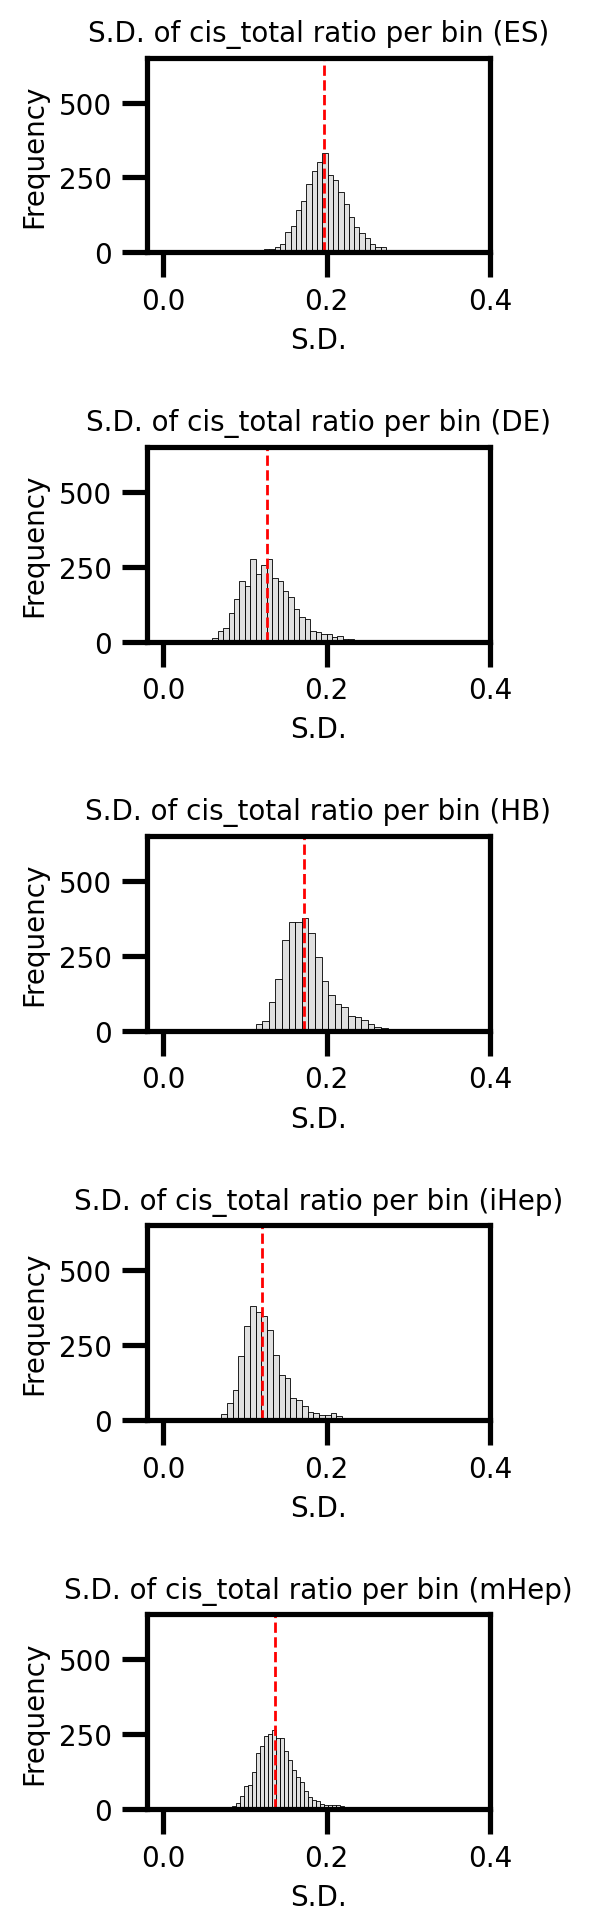

In [ ]:
#histgram show S.D.
# Set up the subplots
fig, axes = plt.subplots(nrows=len(stages2), ncols=1, figsize=(3, 10), dpi=200)

#plate = 'plate6_'
# Iterate over stages2
for i, stage in enumerate(stages2):
    # Access the cosine similarity DataFrame
    df = comp_bin_cisratio[stage].copy()
#    df = comp_bin_cisratio_normalized[stage].copy()
    median = df['cisratio_S.D.'].median()
    
    # Plot the histogram on the corresponding subplot
    sns.histplot(df['cisratio_S.D.'], bins=50, kde=False, color='lightgrey', alpha=0.7, ax=axes[i])
    # Set x-axis limits from 0 to 1
    axes[i].set_xlim(-0.02, 0.4)
    axes[i].set_ylim(0, 650)
#    axes[i].set_title(f'S.D. of cis_total ratio per bin ({stage} of {plate})', fontsize=10)
    axes[i].set_title(f'S.D. of cis_total ratio per bin ({stage})', fontsize=10)
    axes[i].set_xlabel('S.D.', fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    
    axes[i].axvline(x=median, color='red', linestyle='--', lw = 1)
    
    # Set font size for x and y tick labels
    axes[i].tick_params(axis='both', which='major', labelsize=10)
    
# Adjust layout
plt.tight_layout()

plt.savefig(f"/home/xiangru.huo-umw/scHiC/scripts/plot2/Bin_cistrans_S.D.perbin_1M>0.3kb.pdf", 
            format="pdf", bbox_inches="tight")


plt.show()